In [25]:
#fetching lightcurves of positive
import requests
import pandas as pd
from astropy.coordinates import SkyCoord
import astropy.units as u


def get_snad_lightcurve(ra_deg, dec_deg, radius_arcsec=1.2):
    url = "https://db.ztf.snad.space/api/v3/data/dr23/circle/full/json"

    params = {
        "ra": ra_deg,
        "dec": dec_deg,
        "radius_arcsec": radius_arcsec
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()
    return response.json()


catalogue = pd.read_csv("magnetic_cataclysmic_variables.txt")

all_lightcurves = []

# Use .head(5) for testing; remove it to process the full catalogue
for _, row in catalogue.iterrows():

    name = row["Name"]
    ra_str = row["RA(J2000)"]
    dec_str = row["DEC(J2000)"]

    try:
        coord = SkyCoord(
            ra_str,
            dec_str,
            unit=(u.hourangle, u.deg)
        )

        ra_deg = coord.ra.deg
        dec_deg = coord.dec.deg

        payload = get_snad_lightcurve(
            ra_deg,
            dec_deg,
            radius_arcsec=1.2
        )

        object_rows = []

        # Each top-level key represents a ZTF OID
        for oid, source_data in payload.items():

            meta = source_data.get("meta", {})

            # Keep only ZTF r-band sources
            if meta.get("filter") != "zr":
                continue

            observations = source_data.get("lc", [])
            source_coord = meta.get("coord", {})

            for observation in observations:

                # Keep every field returned for each observation
                record = observation.copy()

                # Retain the source OID
                record["oid"] = oid

                # Catalogue target name
                record["object"] = name

                record["ra"] = source_coord.get("ra")
                record["dec"] = source_coord.get("dec")

                object_rows.append(record)

        if object_rows:
            df = pd.DataFrame(object_rows)
            all_lightcurves.append(df)

            print(
                f"{name}: {len(df)} observations "
                f"from {df['oid'].nunique()} OIDs"
            )
        else:
            print(f"{name}: no observations returned")

    except Exception as e:
        print(f"Error fetching {name}: {e}")


# Combine all observations
if all_lightcurves:

    merged = pd.concat(all_lightcurves, ignore_index=True)

    # Ungrouped observation-level data
    merged.to_csv(
        "lightcurves_fetched_from_SNAD.csv",
        index=False
    )

    # Group by catalogue object, preserving the observation order
    grouped = merged.groupby(
        "object",
        sort=False,
        as_index=False
    ).agg(list)

    for col in grouped.columns:
        if col != "object":
            grouped[col] = grouped[col].apply(
                lambda values: ";".join(
                    "" if pd.isna(value) else str(value)
                    for value in values
                )
            )

    # Grouped data, in the same style as your IRSA workflow
    grouped.to_parquet(
        "lightcurves_mcvs.parquet",
        index=False
    )

    print("\nSNAD light curves saved successfully.")
    print("Ungrouped shape:", merged.shape)
    print("Grouped shape:", grouped.shape)
    print("Columns:", merged.columns.tolist())

else:
    print("No SNAD light curves were retrieved.")


V479 And: 1925 observations from 3 OIDs
V1309 Ori: 736 observations from 3 OIDs
AI Tri: 922 observations from 2 OIDs
J0649-0737: no observations returned
MQ Dra: 1304 observations from 2 OIDs
J2048+0050: 420 observations from 1 OIDs
0922+1333: no observations returned
VY For: 156 observations from 1 OIDs
J0227+1306: 665 observations from 2 OIDs
J1740-2418: no observations returned
J1424-0227: no observations returned
QQ Vul: 1528 observations from 2 OIDs
J2340+7642: 593 observations from 3 OIDs
J0749-0549: 630 observations from 2 OIDs
V358 Aqr: 313 observations from 1 OIDs
J1007-2017: 166 observations from 1 OIDs
MN Hya: 34 observations from 1 OIDs
V388 Peg: no observations returned
J1422-0221: no observations returned
V1432 Aql: no observations returned
J1751-2934: no observations returned
BY Cam: no observations returned
V1500 Cyg: 687 observations from 2 OIDs
J0733+2619: 1301 observations from 2 OIDs
J0837+3830: 807 observations from 1 OIDs
V519 Ser: 703 observations from 2 OIDs
J07

J1446+0253: 427 observations from 1 OIDs
V2467 Cyg: 1050 observations from 2 OIDs
J1654-1916: 721 observations from 1 OIDs
V373 Sct: no observations returned
LD 317: no observations returned
AO Psc: 486 observations from 2 OIDs
VZ Sex: 632 observations from 2 OIDs
V647 Aur: 1050 observations from 2 OIDs
J1926+1322: 1309 observations from 1 OIDs
J2014+1529: 1329 observations from 3 OIDs
LS Cam: 948 observations from 2 OIDs
V2400 Oph: no observations returned
J1751-2934: no observations returned
Aqr 1: 430 observations from 1 OIDs
BG CMi: 577 observations from 2 OIDs
V4742 Sgr: no observations returned
J1751-2933#1: no observations returned
J2102+3359: 692 observations from 2 OIDs
V592 Cas: 63 observations from 1 OIDs
V515 And: 1113 observations from 2 OIDs
V795 Her: no observations returned
V2491 Cyg: 991 observations from 3 OIDs
J1751-2929#2: no observations returned
GZ Cnc: no observations returned
J1740-2847: no observations returned
J1751-2929#1: no observations returned
J1751-2933#

In [9]:

# We have a CSV containing negative objects.
# We fetch light curves for the first 1500 objects to compare
# against the 140 CVs (approximately 10x negative examples).

import requests
import pandas as pd
from astropy.coordinates import SkyCoord
import astropy.units as u


# Function to query SNAD ZTF DR23 light curves
def get_snad_lightcurve(ra_deg, dec_deg, radius_arcsec=1.2):
    """
    Query the SNAD API for ZTF light curves around a given RA/Dec.

    Parameters:
        ra_deg (float): Right Ascension in decimal degrees
        dec_deg (float): Declination in decimal degrees
        radius_arcsec (float): Search radius in arcseconds

    Returns:
        JSON response containing ZTF source OIDs, metadata,
        and light-curve observations.
    """
    url = "https://db.ztf.snad.space/api/v3/data/dr23/circle/full/json"

    params = {
        "ra": ra_deg,
        "dec": dec_deg,
        "radius_arcsec": radius_arcsec
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    return response.json()


# Load catalogue of negative objects
# Expected columns: objectId, ra, dec
catalogue = pd.read_csv("negatives.csv")

print(f"Loaded catalogue with {len(catalogue)} objects")

all_lightcurves = []


# Loop through the first 1500 catalogue objects
#catalogue_sample = catalogue.sample(n=min(1500, len(catalogue)), random_state=42)
for i, row in catalogue.head(1500).iterrows():

    object_id = str(row["objectId"])
    ra_deg = float(row["ra"])
    dec_deg = float(row["dec"])

    print(
        f"\n({i + 1}) Querying SNAD for {object_id} "
        f"at RA={ra_deg:.4f}, Dec={dec_deg:.4f}"
    )

    try:
        payload = get_snad_lightcurve(
            ra_deg,
            dec_deg,
            radius_arcsec=1.2
        )

        object_rows = []

        # Each top-level key in the SNAD response represents an OID
        for oid, source_data in payload.items():

            meta = source_data.get("meta", {})

            # Keep only ZTF r-band sources
            if meta.get("filter") != "zr":
                continue

            observations = source_data.get("lc", [])
            source_coord = meta.get("coord", {})

            for observation in observations:

                # Preserve all observation-level fields
                record = observation.copy()

                # Retain the SNAD OID and negative catalogue ID
                record["oid"] = oid
                record["object"] = object_id

                # Source coordinates
                record["ra"] = source_coord.get("ra")
                record["dec"] = source_coord.get("dec")

                object_rows.append(record)

        if object_rows:
            df = pd.DataFrame(object_rows)
            all_lightcurves.append(df)

            print(
                f"   Got {len(df)} r-band observations "
                f"from {df['oid'].nunique()} OIDs "
                f"for {object_id}"
            )
        else:
            print(f"   No data returned for {object_id}")

    except requests.exceptions.Timeout:
        print(f"   Timeout for {object_id} — skipping.")
        continue

    except Exception as e:
        print(f"   Failed for {object_id}: {e}")
        continue


# Save raw merged results
if all_lightcurves:

    merged = pd.concat(all_lightcurves, ignore_index=True)

    # Raw observation-level data
    merged.to_parquet(
        "negatives_lightcurves.parquet",
        index=False
    )

    print(
        f"\nSaved raw light curves with "
        f"{len(merged)} total photometric points."
    )

    # Group observations by catalogue object
    grouped = merged.groupby(
        "object",
        sort=False,
        as_index=False
    ).agg(list)

    # Convert list columns to semicolon-separated strings
    for col in grouped.columns:
        if col != "object":
            grouped[col] = grouped[col].apply(
                lambda values: ";".join(map(str, values))
            )

    # Save grouped data in Parquet format
    grouped.to_parquet(
        "negatives_lightcurves.parquet",
        index=False
    )

    print(
        "Grouped output saved to "
        "'negatives_lightcurves.parquet'"
    )

else:
    print("\nNo r-band light curves were fetched from SNAD.")


Loaded catalogue with 2878 objects

(1) Querying SNAD for ZTF17aaatdnl at RA=92.5702, Dec=20.4072
   Got 1479 r-band observations from 2 OIDs for ZTF17aaatdnl

(2) Querying SNAD for ZTF18aaawejy at RA=98.2217, Dec=15.4851
   Got 1906 r-band observations from 3 OIDs for ZTF18aaawejy

(3) Querying SNAD for ZTF18aaphvtk at RA=92.9264, Dec=19.4704
   Got 1491 r-band observations from 2 OIDs for ZTF18aaphvtk

(4) Querying SNAD for ZTF18aawadfc at RA=282.3956, Dec=15.1392
   Got 1665 r-band observations from 2 OIDs for ZTF18aawadfc

(5) Querying SNAD for ZTF18aawccls at RA=291.6871, Dec=11.3786
   Got 1417 r-band observations from 2 OIDs for ZTF18aawccls

(6) Querying SNAD for ZTF18aawkwln at RA=281.5963, Dec=13.8741
   Got 2569 r-band observations from 2 OIDs for ZTF18aawkwln

(7) Querying SNAD for ZTF18aawsqdu at RA=288.5013, Dec=13.4138
   Got 2019 r-band observations from 2 OIDs for ZTF18aawsqdu

(8) Querying SNAD for ZTF18aawvavc at RA=284.0627, Dec=14.0028
   Got 1753 r-band observatio

In [9]:
#importing useful Python libraries
import pandas as pd
import light_curve as lc
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from functools import reduce #for counting iterations
import joblib
import requests
import time
# Sklearn tools
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,ConfusionMatrixDisplay,precision_score, recall_score, f1_score
#from sklearn.model_selection import cross_val_score
# XGBoost
from xgboost import XGBClassifier


In [10]:
# Load the file with MCV lightcurve data
#this data I used here is my previous data,that I fetched in 2025,not in this notebook 
df = pd.read_parquet("lightcurves_mcvs.parquet")
#find the shape
print("DataFrame loaded with shape:", df.shape)
#print(df.head())

DataFrame loaded with shape: (140, 8)


In [11]:
# extractor with all features mentioned in this link 'https://github.com/light-curve/light-curve-python'
# definition of all extracted features is reported to my Overleaf file
extractor = lc.Extractor(
    lc.Mean(), #Mean magnitude
    lc.WeightedMean(),
    lc.StandardDeviation(),
    lc.Median(),
    lc.Amplitude(),
    lc.BeyondNStd(nstd=1),
    lc.Cusum(),
    lc.InterPercentileRange(0.10),
    lc.Kurtosis(),
    lc.LinearTrend(),
    lc.LinearFit(),   # slope, slope_sigma, reduced_chi2
    lc.MagnitudePercentageRatio(0.4, .05),
    lc.MagnitudePercentageRatio(0.2, 0.1),
    lc.MaximumSlope(),
    lc.MedianAbsoluteDeviation(),
    lc.MedianBufferRangePercentage(0.10),
    lc.PercentAmplitude(),
    lc.MeanVariance(),
    lc.AndersonDarlingNormal(),
    lc.ReducedChi2(),
    lc.Skew(),
    lc.StetsonK()
)

In [12]:
# Function to parse semicolon-separated arrays
def parse_array(x):
    return np.array([float(v) for v in str(x).split(";") if v != ""])
# Collect results
results = [] #empty array to store results
#Iterate through each row of the DataFrame (each row = one object)
for _, row in df.iterrows():
    try:
        t = parse_array(row["mjd"]) #time array for heleocentric julian date
        m = parse_array(row["mag"]) #magnitude column
        err = parse_array(row["magerr"]) #error
        feats = extractor(t, m, err, sorted=True, check=False)
        results.append([row["object"]] + list(feats))
    except Exception as e:
        print(f" Skipping {row['object']} due to error: {e}")

# Create DataFrame with proper headers
features_df_pos = pd.DataFrame(results, columns=["object"] + extractor.names)

# Save to CSV and Excel
features_df_pos.to_parquet("features_mcvs.parquet", index=False)
print(" Feature extraction complete! Saved to:")
#print("   - lightcurve_features_26.parquet")
#shape
print(features_df_pos.shape)

 Skipping PW Aqr due to error: time-series' length 3 is smaller than the minimum required length 4
 Feature extraction complete! Saved to:
(139, 27)


In [17]:
#correlation matrix for positive features
#correlation calculation
features_pos = features_df_pos.drop(columns=['object'])
corr_pos = features_pos.corr()

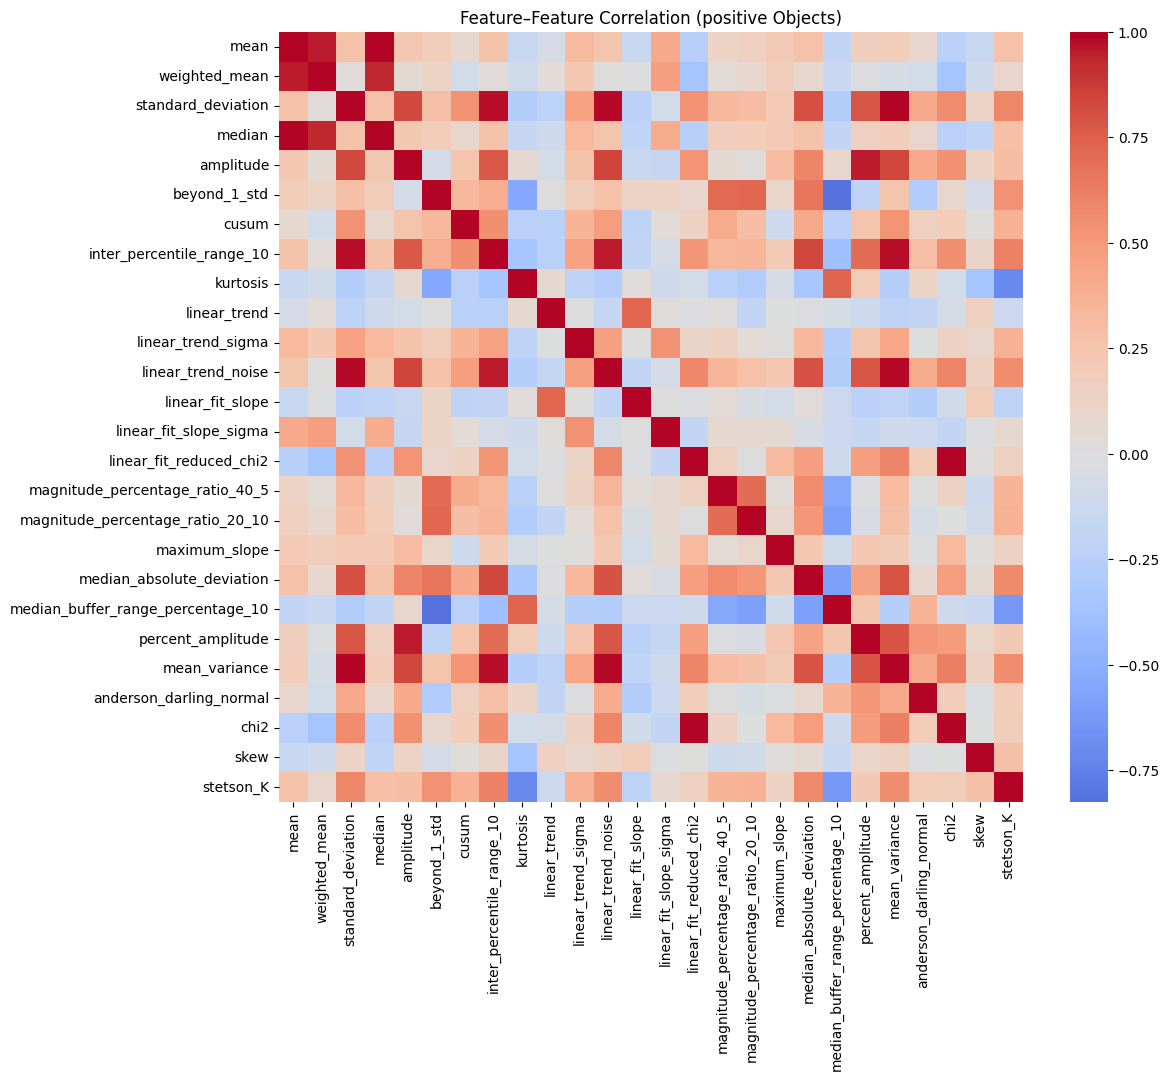

In [18]:
#heatmap plotting
plt.figure(figsize=(12, 10))
sns.heatmap(corr_pos, cmap='coolwarm', center=0)
plt.title('Feature–Feature Correlation (positive Objects)')
#plt.tight_layout()
plt.show()

In [19]:
# Load negative parquet file
df_neg = pd.read_parquet("negatives_lightcurves.parquet")

# Check shape and columns
print(df_neg.shape)
print(df_neg.columns)

(1499, 8)
Index(['object', 'mjd', 'mag', 'magerr', 'clrcoeff', 'oid', 'ra', 'dec'], dtype='object')


In [20]:
# Function to parse semicolon-separated arrays
def parse_array(x):
    return np.array([float(v) for v in str(x).split(";") if v != ""])
# Collect results
results = [] #empty array to store results
#Iterate through each row of the DataFrame (each row = one object) for negative objects
for _, row in df_neg.iterrows():
    try:
        t = parse_array(row["mjd"]) #time array for heleocentric julian date
        m = parse_array(row["mag"]) #magnitude column
        err = parse_array(row["magerr"]) #error
        feats = extractor(t, m, err, sorted=True, check=False)
        results.append([row["object"]] + list(feats))
    except Exception as e:
        print(f" Skipping {row['object']} due to error: {e}")

# Create DataFrame with proper headers
features_df_neg = pd.DataFrame(results, columns=["object"] + extractor.names)

# Save to CSV and Excel
features_df_neg.to_parquet("negative_features.parquet", index=False)
print(" negative_Feature extraction complete! Saved to:")
#print("   - negative_lightcurve_features_26.parquet")
#shape
print(features_df_neg.shape)

 negative_Feature extraction complete! Saved to:
(1499, 27)


In [21]:
# Assuming first column is object and dropping the non numeric entry
features_neg = features_df_neg.drop(columns=['object'])
#correlation matrix calculation
corr_neg = features_neg.corr()

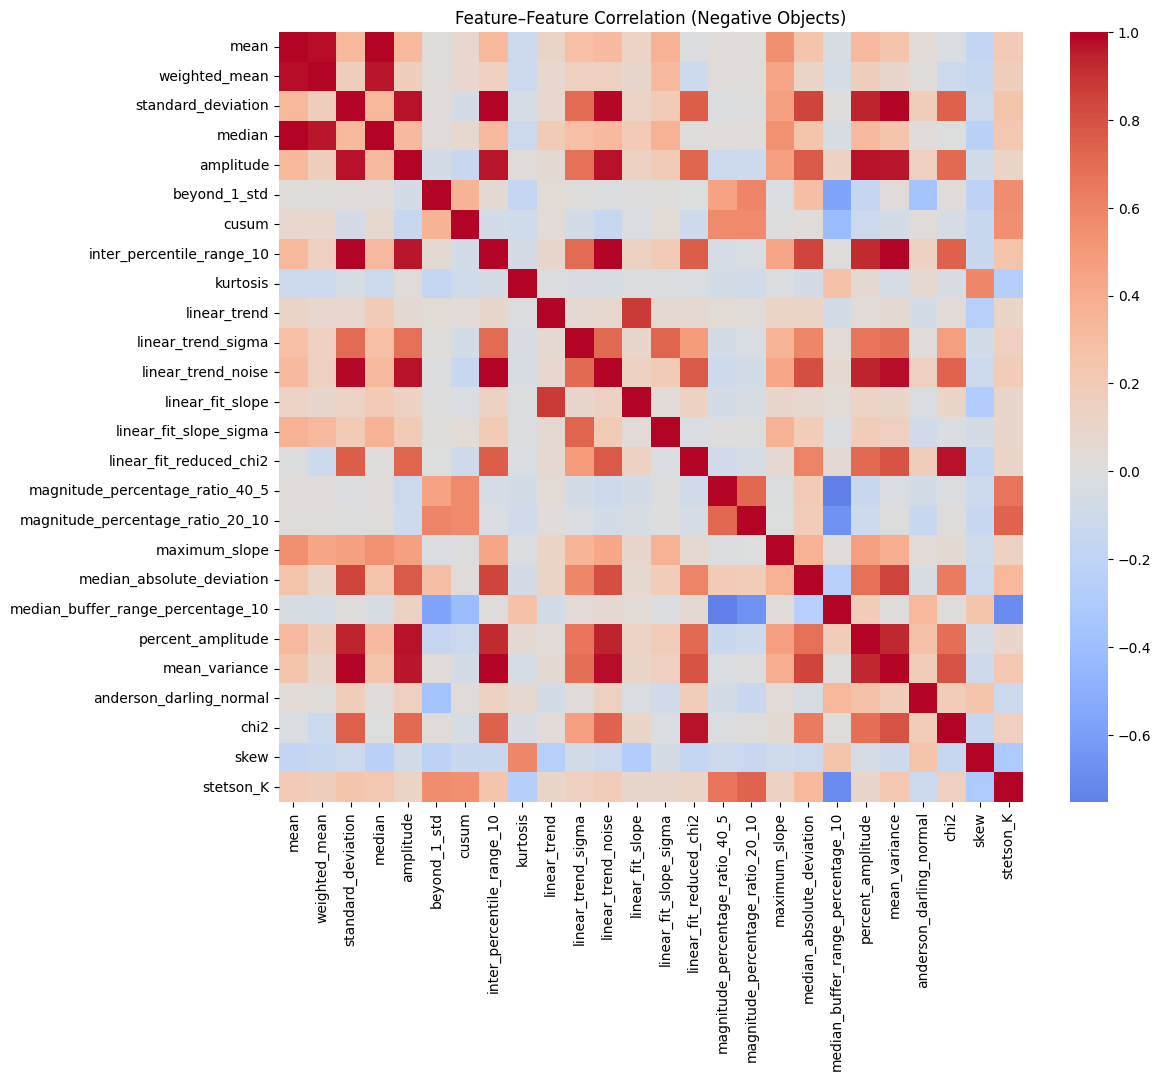

In [22]:
#plotting heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_neg, cmap='coolwarm', center=0)
plt.title('Feature–Feature Correlation (Negative Objects)')
#plt.tight_layout()
plt.show()

In [23]:
# corr_cv and corr_neg diff correlation matrices
corr_diff = corr_pos - corr_neg

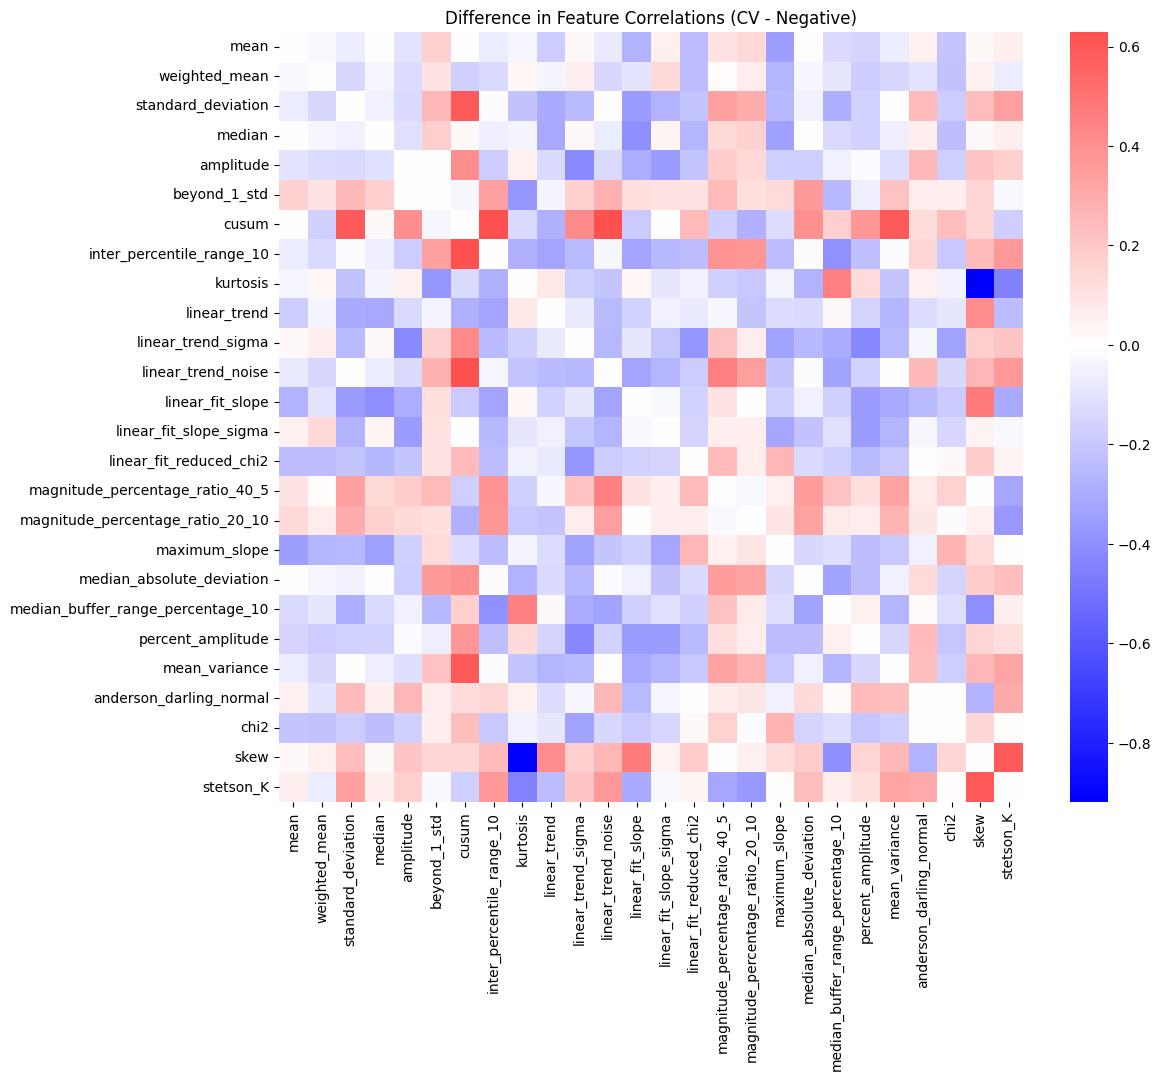

In [24]:
#difference between correlation f pos and neg
plt.figure(figsize=(12, 10))
sns.heatmap(corr_diff, cmap='bwr', center=0)
plt.title('Difference in Feature Correlations (CV - Negative)')
#plt.tight_layout()
plt.show()

In [31]:
#  Convert to long (pairwise) format
corr_diff_pairs = corr_diff.unstack()

#  Drop self-correlations (feature vs itself)
corr_diff_pairs = corr_diff_pairs[corr_diff_pairs.index.get_level_values(0) != corr_diff_pairs.index.get_level_values(1)]

#  Keep only one of (A,B) and (B,A) pairs to avoid duplication
corr_diff_pairs = corr_diff_pairs[ [i < j for i, j in corr_diff_pairs.index] ]

#  Sort by absolute difference
corr_diff_pairs = corr_diff_pairs.reindex(corr_diff_pairs.abs().sort_values(ascending=False).index)

#  Select feature pairs with large correlation difference
# e.g., absolute difference > 0.5, 0.5 because halfway diff is taken
high_corr_diff = corr_diff_pairs[abs(corr_diff_pairs) > 0.5]

print("Feature pairs with largest correlation difference between positive and negative sets:")
print(high_corr_diff)

Feature pairs with largest correlation difference between positive and negative sets:
kurtosis  skew                        -0.919203
cusum     inter_percentile_range_10    0.629357
          linear_trend_noise           0.627739
          standard_deviation           0.592965
          mean_variance                0.592893
skew      stetson_K                    0.590540
dtype: float64


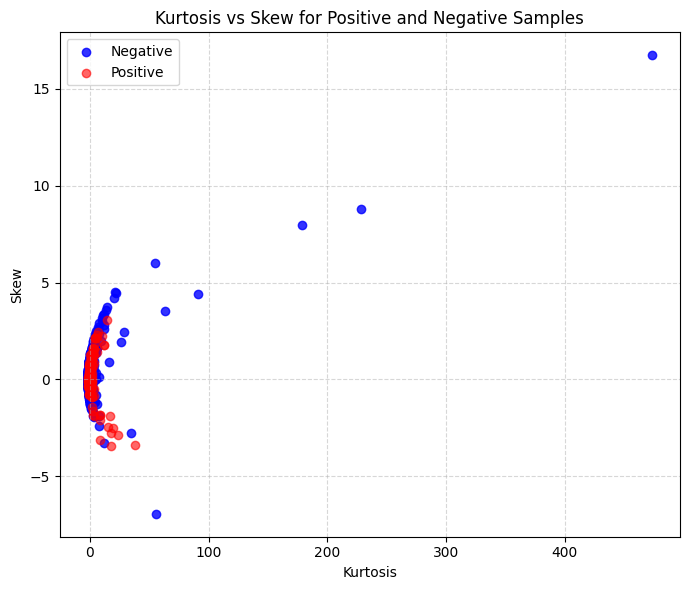

In [32]:
#skew and kurtosis
plt.figure(figsize=(7, 6))
# Plot negatives
plt.scatter(features_neg['kurtosis'], features_neg['skew'],
            color='blue', alpha=0.8, label='Negative')

# Plot positives
plt.scatter(features_pos['kurtosis'], features_pos['skew'],
            color='red', alpha=0.6, label='Positive')



plt.xlabel('Kurtosis')
plt.ylabel('Skew')
plt.title('Kurtosis vs Skew for Positive and Negative Samples')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

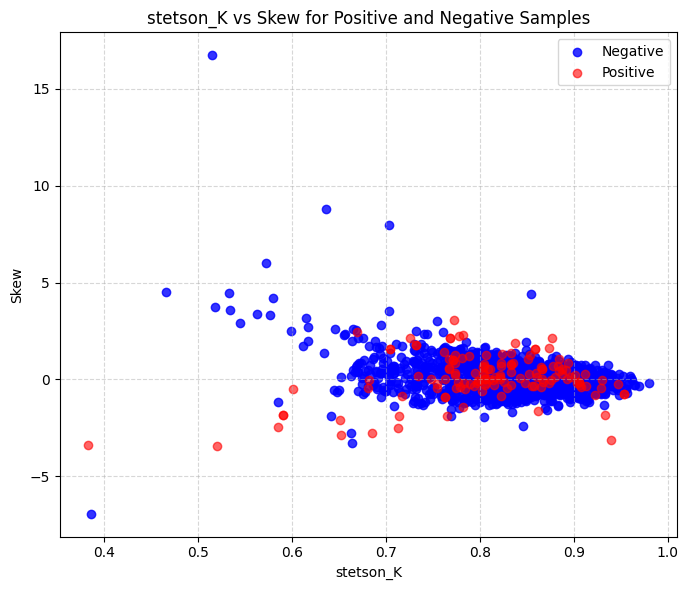

In [33]:
#skew and stetson_k

plt.figure(figsize=(7, 6))
# Plot negatives
plt.scatter(features_neg['stetson_K'], features_neg['skew'],
            color='blue', alpha=0.8, label='Negative')

# Plot positives
plt.scatter(features_pos['stetson_K'], features_pos['skew'],
            color='red', alpha=0.6, label='Positive')



plt.xlabel('stetson_K')
plt.ylabel('Skew')
plt.title('stetson_K vs Skew for Positive and Negative Samples')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

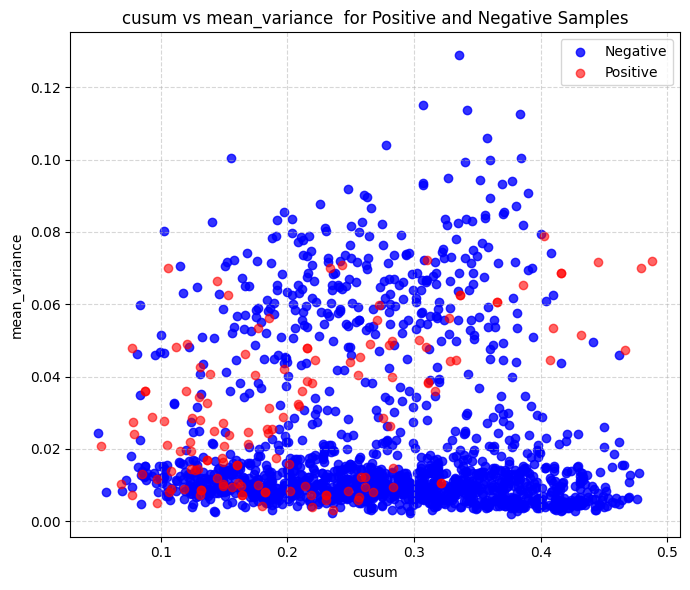

In [34]:
#cumulative sum and mean varience

plt.figure(figsize=(7, 6))

# Plot negatives
plt.scatter(features_neg['cusum'], features_neg['mean_variance'],
            color='blue', alpha=0.8, label='Negative')


# Plot positives
plt.scatter(features_pos['cusum'], features_pos['mean_variance'],
            color='red', alpha=0.6, label='Positive')


plt.xlabel('cusum')
plt.ylabel('mean_variance')
plt.title('cusum vs mean_variance  for Positive and Negative Samples')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

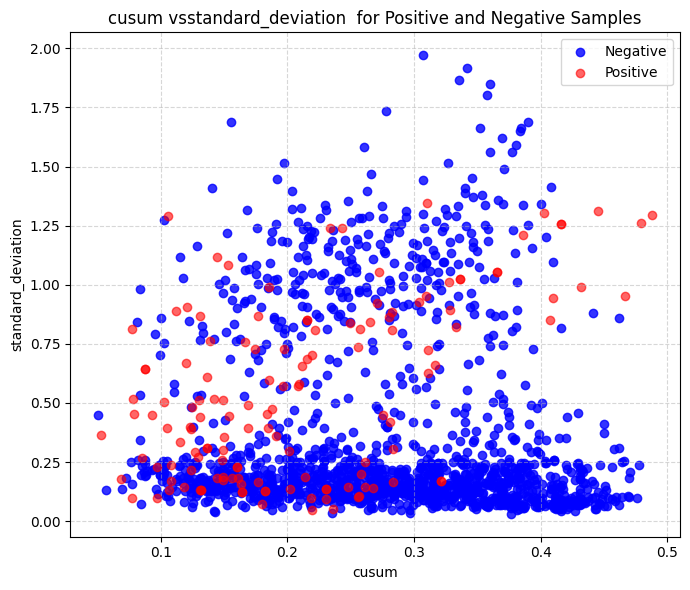

In [35]:
#cumulative sum & standard deviation
plt.figure(figsize=(7, 6))

# Plot negatives
plt.scatter(features_neg['cusum'], features_neg['standard_deviation'],
            color='blue', alpha=0.8, label='Negative')
# Plot positives
plt.scatter(features_pos['cusum'], features_pos['standard_deviation'],
            color='red', alpha=0.6, label='Positive')



plt.xlabel('cusum')
plt.ylabel('standard_deviation')
plt.title('cusum vsstandard_deviation  for Positive and Negative Samples')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

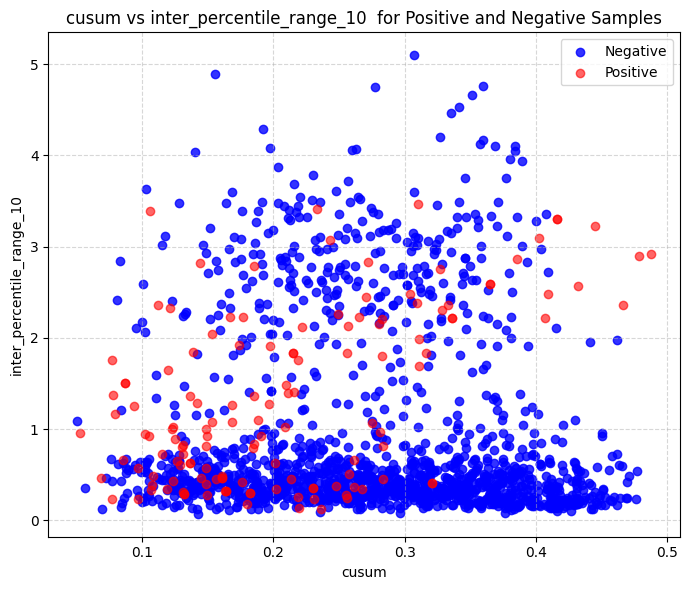

In [37]:
#cumulative sum & inter_percentile_range_10
plt.figure(figsize=(7, 6))

# Plot negatives
plt.scatter(features_neg['cusum'], features_neg['inter_percentile_range_10'],
            color='blue', alpha=0.8, label='Negative')
# Plot positives
plt.scatter(features_pos['cusum'], features_pos['inter_percentile_range_10'],
            color='red', alpha=0.6, label='Positive')



plt.xlabel('cusum')
plt.ylabel('inter_percentile_range_10')
plt.title('cusum vs inter_percentile_range_10  for Positive and Negative Samples')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

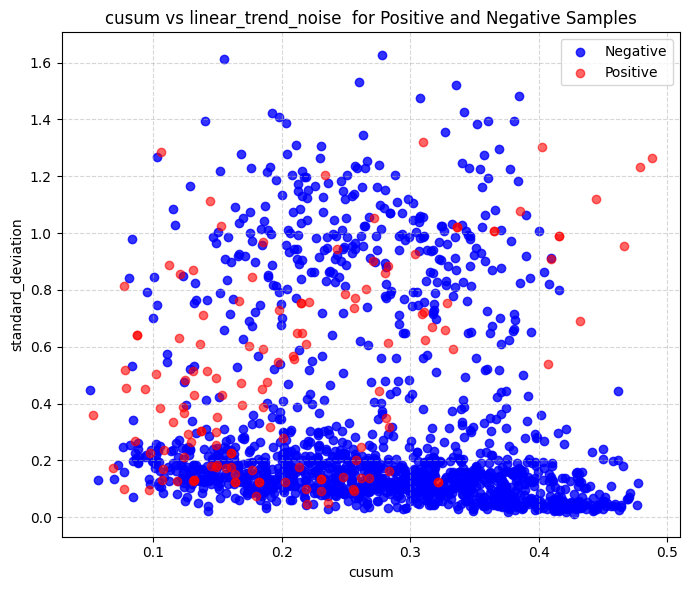

In [38]:
#cumulative sum & standard deviation
plt.figure(figsize=(7, 6))

# Plot negatives
plt.scatter(features_neg['cusum'], features_neg['linear_trend_noise'],
            color='blue', alpha=0.8, label='Negative')
# Plot positives
plt.scatter(features_pos['cusum'], features_pos['linear_trend_noise'],
            color='red', alpha=0.6, label='Positive')



plt.xlabel('cusum')
plt.ylabel('standard_deviation')
plt.title('cusum vs linear_trend_noise  for Positive and Negative Samples')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [39]:
# lightcurve feature dataset for Mcvs and non-Mcv(unknowns)
positives=pd.read_parquet('features_mcvs.parquet')
negatives=pd.read_parquet('negative_features.parquet')

In [40]:
#combine them
combined = pd.concat([positives,negatives])
# Shuffle the combined dataset
combined = combined.sample(frac=1)#.reset_index(drop=True)
#save
combined.to_parquet("SNAD_data.parquet", index=False)
#print shape
print("Combined and shuffled dataset saved")
print("Total rows:", len(combined))

Combined and shuffled dataset saved
Total rows: 1638


In [41]:
#load combined data
df=pd.read_parquet("SNAD_data.parquet")

In [42]:
#keep numeic values only
#X
X = df.drop(columns=['object']).values

In [43]:
# object column contains names like 'ZTF18abc...' or non-ZTF names : Binary conversion of objects
y = np.where(df['object'].str.contains('ZTF', case=False),
             0,   # for my case ZTF=negative
              1)   # non-ZTF = positive

In [75]:
#varying random seeds in different run
SEED = 12#58 #42 #32 #24 #12
#varying train size and n estimator size to get best values
train_sizes = np.arange(0.5, 0.91, 0.1)   # train size
n_estimators = np.arange(50, 201, 20)      # number of trees

results = []

for size in train_sizes:

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        train_size=size,
        shuffle=True,
        random_state=SEED,
        # stratify=y
    )

    # Count classes in this train/test split
    train_positive = np.sum(y_train == 1)
    train_negative = np.sum(y_train == 0)

    test_positive = np.sum(y_test == 1)
    test_negative = np.sum(y_test == 0)

    for n in n_estimators:

        # XGBoost model
        model = XGBClassifier(
            n_estimators=n,
            max_depth=10, #keeping them fixed
            learning_rate=0.3,
            eval_metric='logloss',
            random_state=SEED
        )

        # Model fitting
        model.fit(X_train, y_train)

        # Prediction
        y_pred = model.predict(X_test)

        # Evaluation
        acc = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred, pos_label=1)
        recall = recall_score(y_test, y_pred, pos_label=1)
        f1 = f1_score(y_test, y_pred, pos_label=1)

        # Store results
        results.append({
            "train_size": size,
            "n_estimators": n,
            "max_depth": 10,
            "learning_rate": 0.3,

            # Class counts
            "train_positive": train_positive,
            "train_negative": train_negative,
            "test_positive": test_positive,
            "test_negative": test_negative,

            # Performance
            "accuracy": acc,
            "precision": precision,
            "recall": recall,
            "f1_score": f1
        })

results_df = pd.DataFrame(results)

In [76]:
# Find best configuration based on precision
best_row = results_df.loc[results_df["precision"].idxmax()]

best_train_size = best_row["train_size"]
best_n_estimators = best_row["n_estimators"]
best_max_depth = best_row["max_depth"]
best_learning_rate = best_row["learning_rate"]

# Training and test class counts
best_train_positive = best_row["train_positive"]
best_train_negative = best_row["train_negative"]
best_test_positive = best_row["test_positive"]
best_test_negative = best_row["test_negative"]

# Performance metrics
best_accuracy = best_row["accuracy"]
best_precision = best_row["precision"]
best_recall = best_row["recall"]
best_f1 = best_row["f1_score"]

print("Best configuration based on precision:")
print(f"Train size        : {best_train_size}")
print(f"n_estimators      : {best_n_estimators}")
print(f"max_depth         : {best_max_depth}")
print(f"learning_rate     : {best_learning_rate}")

print("\nTraining set:")
print(f"CV (positive)     : {int(best_train_positive)}")
print(f"Unknown (negative): {int(best_train_negative)}")
print(f"Total             : {int(best_train_positive + best_train_negative)}")

print("\nTest set:")
print(f"CV (positive)     : {int(best_test_positive)}")
print(f"Unknown (negative): {int(best_test_negative)}")
print(f"Total             : {int(best_test_positive + best_test_negative)}")

print("\nTest performance:")
print(f"Accuracy           : {best_accuracy:.4f}")
print(f"Precision          : {best_precision:.4f}")
print(f"Recall             : {best_recall:.4f}")
print(f"F1-score           : {best_f1:.4f}")

# Save best configuration
best_row.to_frame().T.to_csv(
    "configure_58.csv",
    index=False
)

Best configuration based on precision:
Train size        : 0.6
n_estimators      : 70.0
max_depth         : 10.0
learning_rate     : 0.3

Training set:
CV (positive)     : 80
Unknown (negative): 902
Total             : 982

Test set:
CV (positive)     : 59
Unknown (negative): 597
Total             : 656

Test performance:
Accuracy           : 0.9695
Precision          : 0.8980
Recall             : 0.7458
F1-score           : 0.8148


In [77]:
#train the best model
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=best_train_size,
    #stratify=y,
    random_state=12 #58#42 #32 #24#12
)
#best model with best parameters
best_model = XGBClassifier(
    n_estimators=int(best_n_estimators),
    max_depth=int(best_max_depth),
    learning_rate=float(best_learning_rate),
    eval_metric='logloss',
    n_jobs=-1
)
#fit best model
best_model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [78]:
#predict model
y_pred = best_model.predict(X_test)
#print(y_pred)
#accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))
#precision
print("Precision:", precision_score(y_test, y_pred))
probs = best_model.predict_proba(X_test)
#print('probs',probs)

Accuracy: 0.9695121951219512
Precision: 0.8979591836734694


Confusion matrix (raw counts):
[[592   5]
 [ 15  44]]


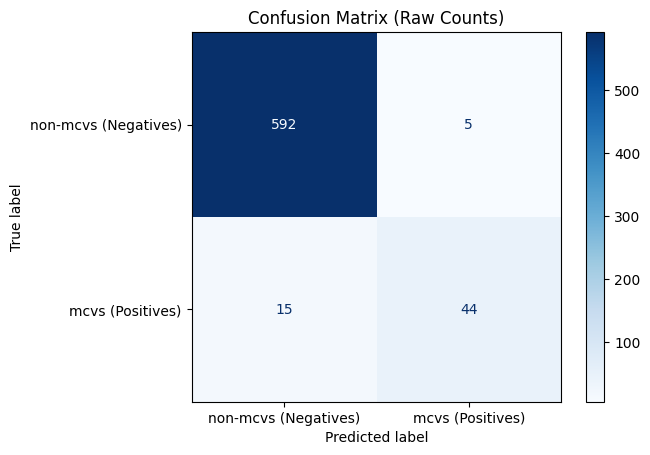

In [79]:
# For best model CONFUSION MATRIX + TP / TN / FP / FN IDENTIFICATION
# Class labels for clarity
class_names = ["non-mcvs (Negatives)", "mcvs (Positives)"]

# Plot confusion matrix (raw counts)
disp = ConfusionMatrixDisplay.from_estimator(
   best_model,
    X_test,
    y_test,
    display_labels=class_names,
    cmap=plt.cm.Blues #heatmap
)

disp.ax_.set_title("Confusion Matrix (Raw Counts)")
print("Confusion matrix (raw counts):")
print(disp.confusion_matrix)

plt.show()


# Extract TN, FP, FN, TP explicitly
# Label convention used in  code:
#   0 :ZTF names (negative, non-CV)
#   +1 :non-ZTF names (positive, CV)

cm = confusion_matrix(y_test, best_model.predict(X_test), labels=[0, 1])

TN, FP, FN, TP = cm.ravel()

In [80]:
#saving the best model
joblib.dump(best_model, "model_12_1.pkl")

['model_12_1.pkl']

In [4]:
# Import useful Python libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import time

# Load dataset
df_test = pd.read_parquet("my_dataset.parquet")
print("Total rows:", len(df_test))
#df_test = df_test.head(5)
# Null array
all_rows = []

# Process objects
for i in range(len(df_test)):

    object_id = df_test["objectId"].iloc[i]
    print(f"Processing {i+1}: {object_id}")
    # Take mean RA and Dec
    ra = np.mean(df_test["ra"].iloc[i])
    dec = np.mean(df_test["dec"].iloc[i])

    # Fink class as first entry
    finkclass = df_test["finkclass"].iloc[i][0]

    try:
        # Query SNAD
        url = "https://db.ztf.snad.space/api/v3/data/latest/circle/full/json"

        params = {
            "ra": ra,
            "dec": dec,
            "radius_arcsec": 1.2
        }

        r = requests.get(url, params=params, timeout=60)
        r.raise_for_status()

        data = r.json()

        # Skip if no data returned
        if len(data) == 0:
            continue

        # Extract light curves
        for name in data:
            filt = data[name].get("meta", {}).get("filter", None)

            # Keep only r-band data
            if filt == "zr":
                lc = data[name].get("lc", [])

                for point in lc:
                    all_rows.append({
                        "objectId": object_id,
                        "finkclass": finkclass,
                        "oid": name,
                        "mjd": point.get("mjd"),
                        "mag": point.get("mag"),
                        "magerr": point.get("magerr"),
                        #"filter": filt
                    })

    except Exception as e:
        print("Error fetching", object_id, e)

    # Optional delay between requests
    # time.sleep(0.5)

# Create dataframe
final_df = pd.DataFrame(all_rows)

print("Total photometry rows collected:", len(final_df))

if not final_df.empty:

    # Save raw photometry data
    final_df.to_parquet("snad_lightcurves_raw.parquet", index=False)

    # Group by objectId
    grouped_df = final_df.groupby("objectId", sort=False).agg({
        "finkclass": "first",
        "oid": list,
        "mjd": list,
        "mag": list,
        "magerr": list,
        #"filter": list
    }).reset_index()

    print("Objects after grouping:", len(grouped_df))

    # Save grouped output
    grouped_df.to_parquet(
        "snad_lightcurves_grouped.parquet",
        index=False
    )

    print("Saved raw file: snad_lightcurves_raw.parquet")
    print("Saved grouped file: snad_lightcurves_grouped.parquet")

    # Display result
    #print(grouped_df.head())

else:
    print("No SNAD r-band light curves were collected.")


Total rows: 2184
Processing 1: ZTF19adbqerg
Processing 2: ZTF18aadggvs
Processing 3: ZTF20aceobuz
Processing 4: ZTF18abcpvwv
Processing 5: ZTF19aapgrjj
Processing 6: ZTF18adqxcfv
Processing 7: ZTF18aalmafg
Processing 8: ZTF22abucnoy
Processing 9: ZTF17aaaitci
Processing 10: ZTF18admdrpn
Processing 11: ZTF18abzyqas
Processing 12: ZTF18acykodj
Processing 13: ZTF20actnqzc
Processing 14: ZTF18acuxbmu
Processing 15: ZTF17aaciptm
Processing 16: ZTF18acayemj
Processing 17: ZTF18aafucqf
Processing 18: ZTF19acveysb
Processing 19: ZTF19aapzxlt
Processing 20: ZTF19acdrlfz
Processing 21: ZTF17aaatvny
Processing 22: ZTF18abgopgb
Processing 23: ZTF18aazndpb
Processing 24: ZTF18aculmrj
Processing 25: ZTF18abmnwmk
Processing 26: ZTF18acgvlmp
Processing 27: ZTF18acpszwx
Processing 28: ZTF18acfhcna
Processing 29: ZTF20abcosov
Processing 30: ZTF19aaailog
Processing 31: ZTF18abccsmp
Processing 32: ZTF19acubskr
Processing 33: ZTF18aahbzdk
Processing 34: ZTF18adaqhkn
Processing 35: ZTF18aaoekzw
Processing 3

In [16]:
df_new=pd.read_parquet("snad_lightcurves_grouped.parquet")
#extracting the statistical features from lightcurve info
results = []

for _, row in df_new.iterrows():

    try:
        t = np.array(row["mjd"])
        m = np.array(row["mag"])
        err = np.array(row["magerr"])

        feats = extractor(
            t, m, err,
            sorted=True,
            check=False
        )

        # If extractor returns a dictionary
        if isinstance(feats, dict):
            feature_values = [feats[name] for name in extractor.names]
        else:
            feature_values = list(feats)

        results.append(
            [row["objectId"], row["finkclass"]] + feature_values
        )

    except Exception as e:
        print(
            f"Skipping {row['objectId']} due to error: {e}"
        )
# Create dataframe
features_df = pd.DataFrame(
    results,
    columns=["objectId", "finkclass"] + list(extractor.names)
)
# Save feature space
features_df.to_parquet(
    "my_feature_space.parquet",
    index=False
)
print("Feature extraction complete!")
#print("Keys", features_df.keys)
#print("Shape:", features_df.shape)

Feature extraction complete!


Total individual light curves: 4159


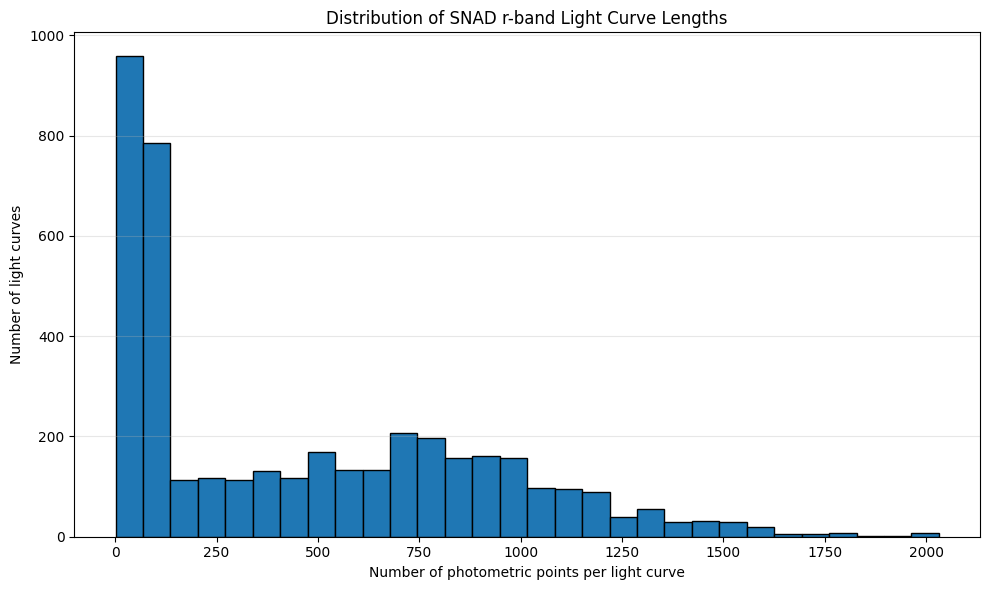

In [17]:
# Load the saved raw SNAD light curves
df = pd.read_parquet("snad_lightcurves_raw.parquet")

# Count points in each individual light curve
points_per_lc = df.groupby(["objectId", "oid"]).size()

print("Total individual light curves:", len(points_per_lc))

# Plot histogram
plt.figure(figsize=(10, 6))
plt.hist(points_per_lc, bins=30, edgecolor="black")

plt.xlabel("Number of photometric points per light curve")
plt.ylabel("Number of light curves")
plt.title("Distribution of SNAD r-band Light Curve Lengths")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:
#load all models
model_12=joblib.load("model_12.pkl")
model_24=joblib.load("model_24.pkl")
model_32=joblib.load("model_32.pkl")
model_42=joblib.load("model_42.pkl")
model_58=joblib.load("model_58.pkl")
model_12_1=joblib.load("model_12_1.pkl")

In [19]:
#load new fink data
df = pd.read_parquet("my_feature_space.parquet")
#feature space
feature_columns = df.drop(columns=['objectId', 'finkclass']).columns #drop non_numeric columns
#features
X = df[feature_columns].values #feature column
#predict model
y_pred_12 = model_12.predict(X) 
y_pred_24 = model_24.predict(X)
y_pred_32 = model_32.predict(X)
y_pred_42 = model_42.predict(X)
y_pred_58 = model_58.predict(X)
y_pred_12_1 = model_12_1.predict(X)
#print("Unique predictions:", np.unique(y_pred_12)) #cross check

In [21]:
# Check class probabilities for the test set.
# predict_proba returns an array of shape (N_test, 2),
# where N_test is the number of test objects.
# Column 0 : probability of class 0 (negative, unknown)
# Column 1 : probability of class +1 (positive, cvs)
probs_12 = model_12.predict_proba(X)
probs_24 = model_24.predict_proba(X)
probs_32 = model_32.predict_proba(X)
probs_42 = model_42.predict_proba(X)
probs_58 = model_58.predict_proba(X)
probs_12_1 = model_12_1.predict_proba(X)




#print('probs',probs)

In [22]:
# CV probability with finkclass_column_atached
cv_prob_12 = probs_12[:,1]
cv_prob_24 = probs_24[:,1]
cv_prob_32 = probs_32[:,1]
cv_prob_42 = probs_42[:,1]
cv_prob_58 = probs_58[:,1]
cv_prob_12_1 = probs_12_1[:,1]

# create dataframe with required columns
prob_df_12= pd.DataFrame({
    "objectId": df["objectId"],
    "finkclass": df["finkclass"],
    "cv_probability": cv_prob_12
})
prob_df_24= pd.DataFrame({
    "objectId": df["objectId"],
    "finkclass": df["finkclass"],
    "cv_probability": cv_prob_24
})
prob_df_32= pd.DataFrame({
    "objectId": df["objectId"],
    "finkclass": df["finkclass"],
    "cv_probability": cv_prob_32
})
prob_df_42= pd.DataFrame({
    "objectId": df["objectId"],
    "finkclass": df["finkclass"],
    "cv_probability": cv_prob_42
})
prob_df_58= pd.DataFrame({
    "objectId": df["objectId"],
    "finkclass": df["finkclass"],
    "cv_probability": cv_prob_58
})
prob_df_12_1= pd.DataFrame({
    "objectId": df["objectId"],
    "finkclass": df["finkclass"],
    "cv_probability": cv_prob_12_1
})


In [23]:
#probablity distribution checking
high_prob_12 = prob_df_12[prob_df_12["cv_probability"] > 0.9]
high_prob_24 = prob_df_24[prob_df_24["cv_probability"] > 0.9]
high_prob_32 = prob_df_32[prob_df_32["cv_probability"] > 0.9]
high_prob_42 = prob_df_42[prob_df_42["cv_probability"] > 0.9]
high_prob_58 = prob_df_58[prob_df_58["cv_probability"] > 0.9]
high_prob_12_1 = prob_df_12_1[prob_df_12_1["cv_probability"] > 0.9]

In [24]:
#saving into parquet
high_prob_12.to_csv("cv_above_0.9_RS_12.csv", index=False)
high_prob_24.to_csv("cv_above_0.9_RS_24.csv", index=False)
high_prob_32.to_csv("cv_above_0.9_RS_32.csv", index=False)
high_prob_42.to_csv("cv_above_0.9_RS_42.csv", index=False)
high_prob_58.to_csv("cv_above_0.9_RS_58.csv", index=False)
high_prob_12_1.to_csv("cv_above_0.9_RS_12_1.csv", index=False)

In [27]:
# output files for all models
files = {
    "RS_12": "cv_above_0.9_RS_12.csv",
    "RS_24": "cv_above_0.9_RS_24.csv",
    "RS_32": "cv_above_0.9_RS_32.csv",
    "RS_42": "cv_above_0.9_RS_42.csv",
    "RS_58": "cv_above_0.9_RS_58.csv",
    "RS_12_1": "cv_above_0.9_RS_12_1.csv"
}


# Keep finkclass from RS_12 as finkclass is same of the objects
finkclass_df = pd.read_csv(
    files["RS_12"],
    usecols=["objectId", "finkclass"]
)

# Read each CSV
dfs = {}

for name, file in files.items():

    df = pd.read_csv(file)

    # Keep objectId and CV probability
    df = df[["objectId", "cv_probability"]].copy()

    # Rename probability column
    df = df.rename(columns={
        "cv_probability": f"CV_probability_{name}"
    })

    dfs[name] = df


# Merge all files using OUTER JOIN
merged_df = reduce(
    lambda left, right: pd.merge(
        left,
        right,
        on="objectId",
        how="outer"
    ),
    dfs.values()
)


# Add finkclass
merged_df = pd.merge(
    merged_df,
    finkclass_df,
    on="objectId",
    how="left"
)


# Find probability columns
probability_columns = [
    col for col in merged_df.columns
    if col.startswith("CV_probability_")
]


# Count how many files contain each object
merged_df["number_of_files"] = (
    merged_df[probability_columns]
    .notna()
    .sum(axis=1)
)


# Create a column showing which files contain each object
def find_common_files(row):

    common_files = []

    for name in files.keys():

        column = f"CV_probability_{name}"

        if pd.notna(row[column]):
            common_files.append(name)

    return ", ".join(common_files)


merged_df["common_in_files"] = merged_df.apply(
    find_common_files,
    axis=1
)
# Keep ONLY objects present in ALL 6 files
common_objects_all_6 = merged_df[
    merged_df["number_of_files"] == 6
].copy()


# Sort by objectId
common_objects_all_6 = common_objects_all_6.sort_values(
    by="objectId"
)


# Save the result
common_objects_all_6.to_csv(
    "high_probable_mcvs.csv",
    index=False
)


# Print result
print(
    f"Total objects common to all 6 files: "
    f"{len(common_objects_all_6)}"
)


print(
    common_objects_all_6[
        [
            "objectId",
            "finkclass",
            "CV_probability_RS_12",
            "CV_probability_RS_24",
            "CV_probability_RS_32",
            "CV_probability_RS_42",
            "CV_probability_RS_58",
            "CV_probability_RS_12_1"
        ]
    ].head(20)
)

Total objects common to all 6 files: 134
        objectId  finkclass  CV_probability_RS_12  CV_probability_RS_24  \
0   ZTF17aaaadkj  CataclyV*              0.986756              0.963888   
2   ZTF17aaabavb  CataclyV*              0.984047              0.997290   
5   ZTF17aaadasj  CataclyV*              0.997207              0.993236   
7   ZTF17aaaeslm  CataclyV*              0.995245              0.999149   
10  ZTF17aaagywy  CataclyV*              0.987461              0.997524   
17  ZTF17aaaizeq  CataclyV*              0.995722              0.988363   
18  ZTF17aaaizfe  CataclyV*              0.999290              0.999659   
22  ZTF17aaajocf  CataclyV*              0.997846              0.998903   
24  ZTF17aaantxj  CataclyV*              0.994134              0.991672   
27  ZTF17aaarmxh  CataclyV*              0.984047              0.997290   
31  ZTF17aaavfwx  CataclyV*              0.997207              0.993236   
32  ZTF17aaawcro  CataclyV*              0.957063          